In [14]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from google.colab import files

In [15]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses 3 TIC).xlsx to Blank Quiz (Responses 3 TIC) (2).xlsx
File terbaca: Blank Quiz (Responses 3 TIC) (2).xlsx


In [16]:
df = pd.read_excel(nama_file)

butir = df[[c for c in df.columns if re.search(r"\[.*\]\s*$", str(c))]]
print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 40
Jumlah butir     : 29
Data kosong      : 0


In [17]:
skala = {
    "Sangat Tidak Setuju (STJ)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")

print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_989/359578607.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Respon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,5,5,4,4,4,4,4,5,4,4,...,2,5,4,5,4,5,5,4,4,5
1,4,4,4,4,4,4,4,5,4,4,...,4,2,4,4,4,5,4,5,5,5
2,5,5,4,4,4,4,4,4,4,4,...,2,4,5,4,2,5,5,5,4,5
3,5,4,5,2,4,5,5,4,4,2,...,2,4,4,4,4,5,4,4,4,4
4,5,5,4,4,5,5,5,4,2,4,...,2,2,2,2,4,5,5,4,5,5


In [18]:
dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?)\s*\[", kolom).group(1).strip(" .")
    nama = nama.replace("Rsspon", "Respon")
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


In [19]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 40 | r tabel (α=0,05; df=38) = 0.312


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,0.222,0.0071,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,0.224,0.0129,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.626,0.418,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,0.205,0.0009,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.793,0.597,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.634,0.424,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,-0.061,0.1510,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.578,0.437,0.0001,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.708,0.541,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.804,0.651,0.0000,Valid


Reliabilitas per dimensi


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.550,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.678,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.808,Baik
3,Prokrastinasi akademik,4,0.865,Baik
4,Respon emosional,5,0.555,Tidak reliabel



 Penggunaan AI pada tugas atau projek kuliah


,Corrected r,Alpha jika dihapus,Saran
Butir,,,
B1,0.222,0.531,Pertahankan
B2,0.224,0.533,Pertahankan
B3,0.418,0.456,Pertahankan
B4,0.205,0.547,Pertahankan
B5,0.597,0.341,Pertahankan
B6,0.424,0.453,Pertahankan
B7,-0.061,0.639,Tinjau/buang (alpha naik jika dihapus)



 Aspek Psikologis penggunaan AI pada tugas atau projek kuliah


,Corrected r,Alpha jika dihapus,Saran
Butir,,,
B1,0.437,0.637,Pertahankan
B2,0.541,0.597,Pertahankan
B3,0.651,0.550,Pertahankan
B4,0.481,0.614,Pertahankan
B5,0.636,0.555,Pertahankan
B6,0.208,0.684,Tinjau/buang (alpha naik jika dihapus)
B7,-0.272,0.769,Tinjau/buang (alpha naik jika dihapus)


... (2 outputs left out)


 Prokrastinasi akademik


,Corrected r,Alpha jika dihapus,Saran
Butir,,,
B1,0.805,0.790,Pertahankan
B2,0.785,0.798,Pertahankan
B3,0.711,0.829,Pertahankan
B4,0.569,0.886,Tinjau/buang (alpha naik jika dihapus)



 Respon emosional


,Corrected r,Alpha jika dihapus,Saran
Butir,,,
B1,0.625,0.284,Pertahankan
B2,0.297,0.511,Pertahankan
B3,0.340,0.485,Pertahankan
B4,0.065,0.644,Tinjau/buang (alpha naik jika dihapus)
B5,0.331,0.499,Pertahankan


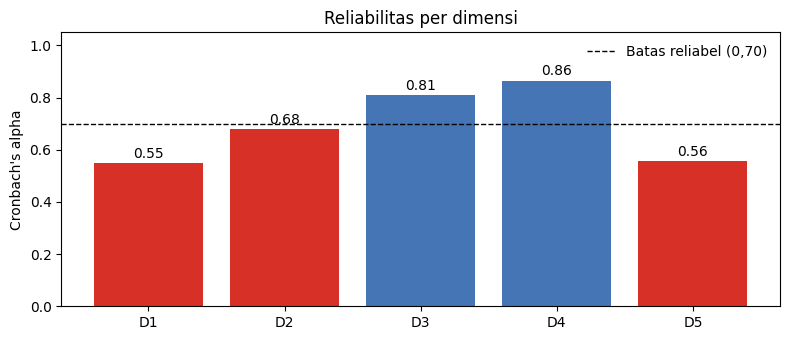

D1–D5 berurutan: ['Penggunaan AI pada tugas atau projek kuliah', 'Aspek Psikologis penggunaan AI pada tugas atau projek kuliah', 'Kebiasaan penggunaan teknologi digital', 'Prokrastinasi akademik', 'Respon emosional']


In [20]:
def cronbach_alpha(x):
    k = x.shape[1]
    var_butir = x.var(ddof=1).sum()
    var_total = x.sum(axis=1).var(ddof=1)
    return k / (k - 1) * (1 - var_butir / var_total)

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas, detail_butir = [], []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    assert a <= 1.0000001, "Alpha > 1 tidak mungkin, periksa data/rumus"
    hasil_reliabilitas.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                               "Cronbach's alpha": round(a, 3), "Kategori": kategori(a)})
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        a_hapus = cronbach_alpha(x.drop(columns=kolom)) if len(daftar) > 2 else np.nan
        r_koreksi = x[kolom].corr(total - x[kolom])
        detail_butir.append({"Dimensi": nama, "Butir": f"B{i}",
                             "Corrected r": round(r_koreksi, 3),
                             "Alpha jika dihapus": round(a_hapus, 3),
                             "Saran": "Tinjau/buang (alpha naik jika dihapus)" if a_hapus > a
                                      else "Pertahankan"})

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_detail_butir = pd.DataFrame(detail_butir)
tabel_alpha_dihapus = tabel_detail_butir[["Dimensi", "Butir", "Alpha jika dihapus"]]

print("Reliabilitas per dimensi")
display(tabel_reliabilitas)
for nama in dimensi:
    print("\n", nama)
    display(tabel_detail_butir[tabel_detail_butir["Dimensi"] == nama]
            .drop(columns="Dimensi").set_index("Butir"))

fig, ax = plt.subplots(figsize=(8, 3.5))
warna = ["#4575b4" if a >= 0.70 else "#d73027" for a in tabel_reliabilitas["Cronbach's alpha"]]
ax.bar([f"D{i}" for i in range(1, len(tabel_reliabilitas) + 1)],
       tabel_reliabilitas["Cronbach's alpha"], color=warna)
ax.axhline(0.70, color="black", ls="--", lw=1, label="Batas reliabel (0,70)")
for i, a in enumerate(tabel_reliabilitas["Cronbach's alpha"]):
    ax.text(i, max(a, 0) + 0.02, f"{a:.2f}", ha="center")
ax.set_ylim(0, 1.05); ax.set_ylabel("Cronbach's alpha"); ax.set_title("Reliabilitas per dimensi")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print("D1–D5 berurutan:", list(dimensi))

In [21]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")
display(gabung)

,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,0.222,0.0071,Valid,0.531
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,0.224,0.0129,Valid,0.533
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.626,0.418,0.0000,Valid,0.456
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,0.205,0.0009,Valid,0.547
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.793,0.597,0.0000,Valid,0.341
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.634,0.424,0.0000,Valid,0.453
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,-0.061,0.1510,Tidak valid,0.639
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.578,0.437,0.0001,Valid,0.637
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.708,0.541,0.0000,Valid,0.597
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.804,0.651,0.0000,Valid,0.550


In [22]:
ringkasan = []
for d_no, (nama, daftar) in enumerate(dimensi.items(), 1):
    v = tabel_validitas[tabel_validitas["Dimensi"] == nama]
    valid = v[v["Keterangan"] == "Valid"]["Butir"].tolist()
    tidak = v[v["Keterangan"] == "Tidak valid"]["Butir"].tolist()
    ringkasan.append({"No": f"D{d_no}", "Dimensi": nama, "Jumlah butir": len(daftar),
                      "Valid": len(valid), "Tidak valid": len(tidak),
                      "Butir valid": ", ".join(valid) or "-",
                      "Butir tidak valid": ", ".join(tidak) or "-"})
ringkasan = pd.DataFrame(ringkasan)
display(ringkasan)

print()
for d_no, (nama, daftar) in enumerate(dimensi.items(), 1):
    v = tabel_validitas[tabel_validitas["Dimensi"] == nama].reset_index(drop=True)
    tidak = v[v["Keterangan"] == "Tidak valid"]
    if tidak.empty:
        print(f"D{d_no} - {nama}: SEMUA BUTIR VALID")
    else:
        print(f"D{d_no} - {nama}: ADA {len(tidak)} BUTIR TIDAK VALID")
        for i in tidak.index:
            teks = re.search(r"\[(.*)\]\s*$", daftar[i]).group(1).strip()
            print(f"    {tidak.loc[i, 'Butir']} (r hitung = {tidak.loc[i, 'r hitung']}, r tabel = {r_tabel:.3f}): {teks}")

,No,Dimensi,Jumlah butir,Valid,Tidak valid,Butir valid,Butir tidak valid
0,D1,Penggunaan AI pada tugas atau projek kuliah,7,6,1,"B1, B2, B3, B4, B5, B6",B7
1,D2,Aspek Psikologis penggunaan AI pada tugas atau...,7,6,1,"B1, B2, B3, B4, B5, B6",B7
2,D3,Kebiasaan penggunaan teknologi digital,6,6,0,"B1, B2, B3, B4, B5, B6",-
3,D4,Prokrastinasi akademik,4,4,0,"B1, B2, B3, B4",-
4,D5,Respon emosional,5,5,0,"B1, B2, B3, B4, B5",-



D1 - Penggunaan AI pada tugas atau projek kuliah: ADA 1 BUTIR TIDAK VALID
    B7 (r hitung = 0.231, r tabel = 0.312): Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.
D2 - Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: ADA 1 BUTIR TIDAK VALID
    B7 (r hitung = -0.094, r tabel = 0.312): Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.
D3 - Kebiasaan penggunaan teknologi digital: SEMUA BUTIR VALID
D4 - Prokrastinasi akademik: SEMUA BUTIR VALID
D5 - Respon emosional: SEMUA BUTIR VALID


DIMENSI: Penggunaan AI pada tugas atau projek kuliah

Distribusi frekuensi jawaban (jumlah responden)


,STS,TS,N,S,SS
B1,0,1,0,20,19
B2,0,0,1,24,15
B3,0,3,0,22,15
B4,1,7,1,27,4
B5,0,7,2,20,11
B6,0,3,0,20,17
B7,1,1,2,19,17


Statistik deskriptif per butir


,Mean,Median,Modus,SD,Min,Max
B1,4.42,4.0,4,0.64,2,5
B2,4.35,4.0,4,0.53,3,5
B3,4.22,4.0,4,0.80,2,5
B4,3.65,4.0,4,0.98,1,5
B5,3.88,4.0,4,1.02,2,5
B6,4.28,4.0,4,0.82,2,5
B7,4.25,4.0,4,0.87,1,5


Rata-rata skor dimensi = 4.15 | SD = 0.43


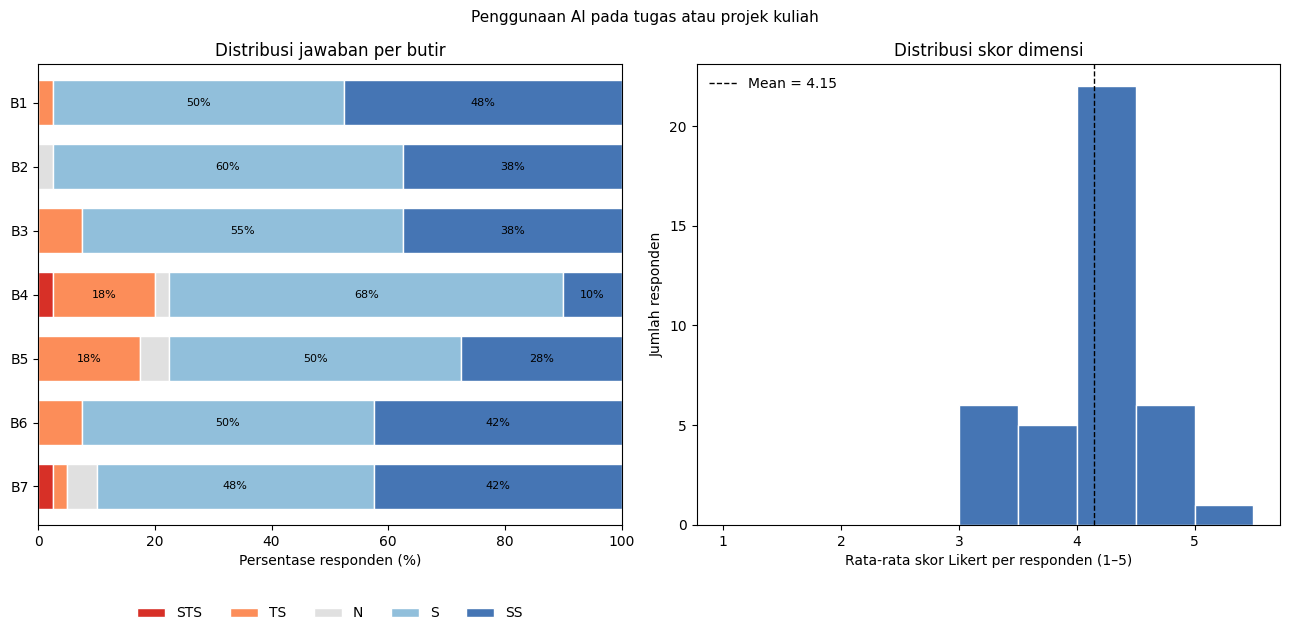

Uji validitas


,r hitung,Corrected r,p-value,Keterangan
Butir,,,,
B1,0.419,0.222,0.0071,Valid
B2,0.390,0.224,0.0129,Valid
B3,0.626,0.418,0.0000,Valid
B4,0.506,0.205,0.0009,Valid
B5,0.793,0.597,0.0000,Valid
B6,0.634,0.424,0.0000,Valid
B7,0.231,-0.061,0.1510,Tidak valid


Uji reliabilitas


,Jumlah butir,Cronbach's alpha,Kategori
0,7,0.55,Tidak reliabel


,Alpha jika dihapus
Butir,
B1,0.531
B2,0.533
B3,0.456
B4,0.547
B5,0.341
B6,0.453
B7,0.639


DIMENSI: Aspek Psikologis penggunaan AI pada tugas atau projek kuliah

Distribusi frekuensi jawaban (jumlah responden)


,STS,TS,N,S,SS
B1,0,3,1,22,14
B2,1,10,3,19,7
B3,6,15,2,13,4
B4,2,15,3,15,5
B5,3,14,0,15,8
B6,1,1,1,18,19
B7,0,3,2,21,14


Statistik deskriptif per butir


,Mean,Median,Modus,SD,Min,Max
B1,4.18,4.0,4.0,0.81,2,5
B2,3.52,4.0,4.0,1.13,1,5
B3,2.85,2.0,2.0,1.31,1,5
B4,3.15,3.5,2.0,1.21,1,5
B5,3.28,4.0,4.0,1.34,1,5
B6,4.32,4.0,5.0,0.86,1,5
B7,4.15,4.0,4.0,0.83,2,5


Rata-rata skor dimensi = 3.64 | SD = 0.64


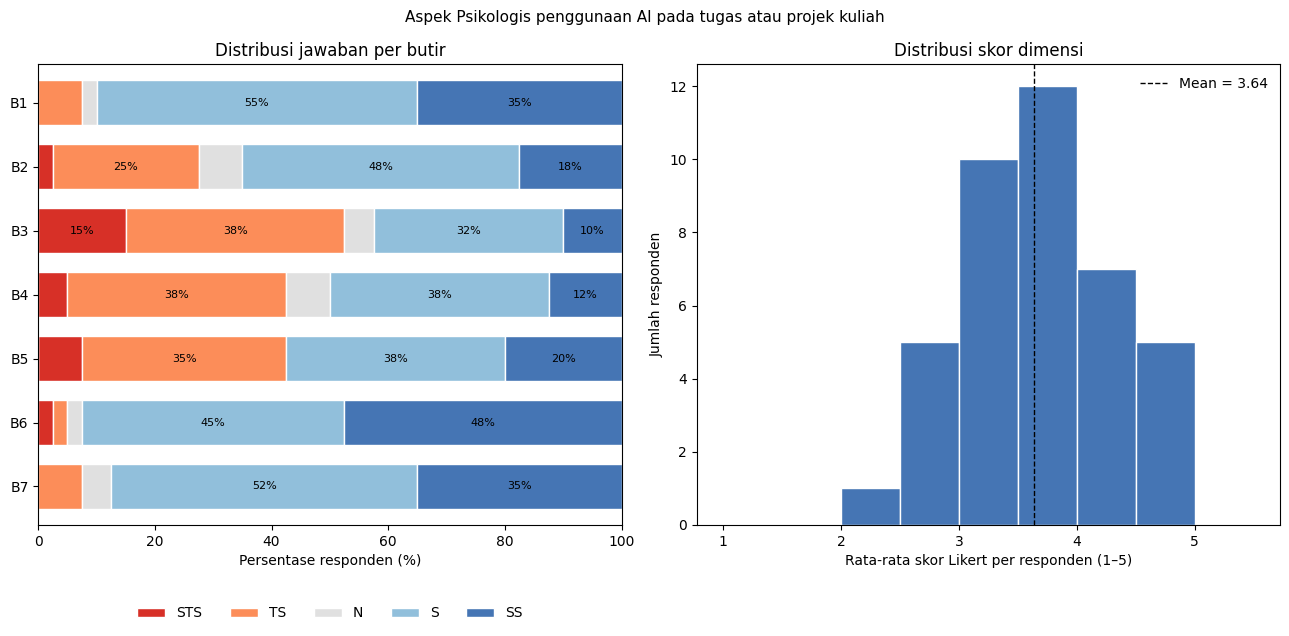

Uji validitas


,r hitung,Corrected r,p-value,Keterangan
Butir,,,,
B1,0.578,0.437,0.0001,Valid
B2,0.708,0.541,0.0000,Valid
B3,0.804,0.651,0.0000,Valid
B4,0.675,0.481,0.0000,Valid
B5,0.797,0.636,0.0000,Valid
B6,0.389,0.208,0.0132,Valid
B7,-0.094,-0.272,0.5625,Tidak valid


Uji reliabilitas


,Jumlah butir,Cronbach's alpha,Kategori
1,7,0.678,Tidak reliabel


,Alpha jika dihapus
Butir,
B1,0.637
B2,0.597
B3,0.550
B4,0.614
B5,0.555
B6,0.684
B7,0.769


DIMENSI: Kebiasaan penggunaan teknologi digital

Distribusi frekuensi jawaban (jumlah responden)


,STS,TS,N,S,SS
B1,0,7,1,19,13
B2,0,5,0,23,12
B3,3,11,0,17,9
B4,4,14,1,13,8
B5,6,15,3,9,7
B6,5,21,0,8,6


Statistik deskriptif per butir


,Mean,Median,Modus,SD,Min,Max
B1,3.95,4.0,4,1.04,2,5
B2,4.05,4.0,4,0.90,2,5
B3,3.45,4.0,4,1.32,1,5
B4,3.18,4.0,2,1.38,1,5
B5,2.90,2.0,2,1.39,1,5
B6,2.72,2.0,2,1.34,1,5


Rata-rata skor dimensi = 3.38 | SD = 0.89


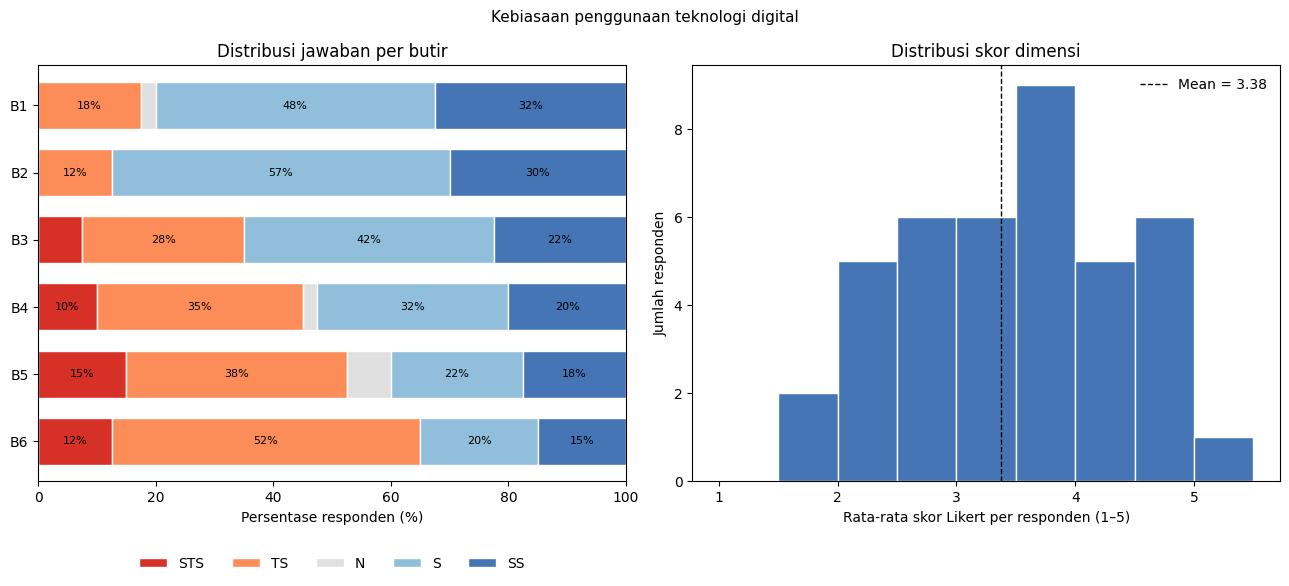

Uji validitas


,r hitung,Corrected r,p-value,Keterangan
Butir,,,,
B1,0.551,0.392,0.0002,Valid
B2,0.567,0.434,0.0001,Valid
B3,0.819,0.706,0.0000,Valid
B4,0.771,0.627,0.0000,Valid
B5,0.796,0.661,0.0000,Valid
B6,0.740,0.587,0.0000,Valid


Uji reliabilitas


,Jumlah butir,Cronbach's alpha,Kategori
2,6,0.808,Baik


,Alpha jika dihapus
Butir,
B1,0.812
B2,0.805
B3,0.744
B4,0.764
B5,0.755
B6,0.774


DIMENSI: Prokrastinasi akademik

Distribusi frekuensi jawaban (jumlah responden)


,STS,TS,N,S,SS
B1,3,14,1,15,7
B2,5,14,1,14,6
B3,2,14,1,16,7
B4,4,9,1,16,10


Statistik deskriptif per butir


,Mean,Median,Modus,SD,Min,Max
B1,3.22,4.0,4.0,1.31,1,5
B2,3.05,3.5,2.0,1.36,1,5
B3,3.30,4.0,4.0,1.26,1,5
B4,3.48,4.0,4.0,1.36,1,5


Rata-rata skor dimensi = 3.26 | SD = 1.12


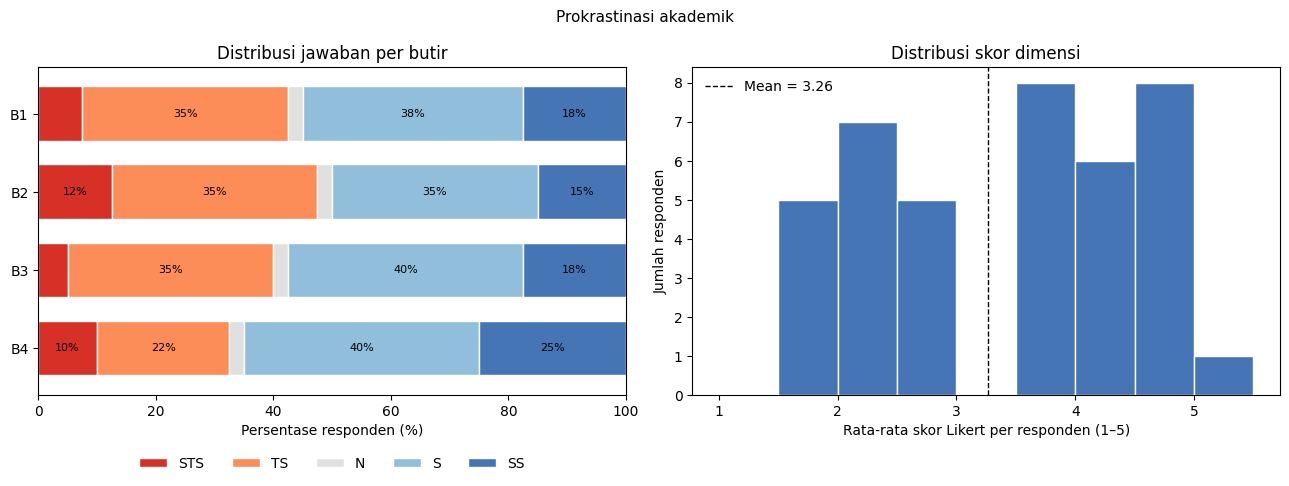

Uji validitas


,r hitung,Corrected r,p-value,Keterangan
Butir,,,,
B1,0.896,0.805,0.0,Valid
B2,0.888,0.785,0.0,Valid
B3,0.837,0.711,0.0,Valid
B4,0.757,0.569,0.0,Valid


Uji reliabilitas


,Jumlah butir,Cronbach's alpha,Kategori
3,4,0.865,Baik


,Alpha jika dihapus
Butir,
B1,0.790
B2,0.798
B3,0.829
B4,0.886


DIMENSI: Respon emosional

Distribusi frekuensi jawaban (jumlah responden)


,STS,TS,N,S,SS
B1,1,4,1,19,15
B2,1,3,1,19,16
B3,1,4,0,20,15
B4,1,6,1,24,8
B5,0,2,1,21,16


Statistik deskriptif per butir


,Mean,Median,Modus,SD,Min,Max
B1,4.08,4.0,4,1.02,1,5
B2,4.15,4.0,4,0.98,1,5
B3,4.10,4.0,4,1.01,1,5
B4,3.80,4.0,4,1.02,1,5
B5,4.28,4.0,4,0.75,2,5


Rata-rata skor dimensi = 4.08 | SD = 0.58


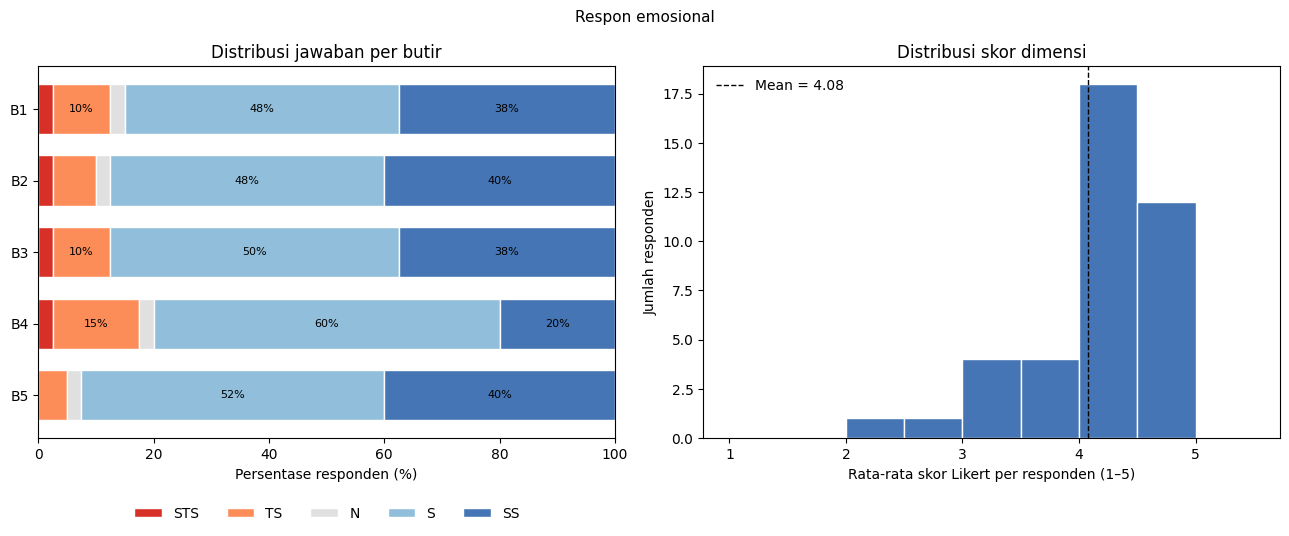

Uji validitas


,r hitung,Corrected r,p-value,Keterangan
Butir,,,,
B1,0.817,0.625,0.0000,Valid
B2,0.590,0.297,0.0001,Valid
B3,0.631,0.340,0.0000,Valid
B4,0.413,0.065,0.0081,Valid
B5,0.553,0.331,0.0002,Valid


Uji reliabilitas


,Jumlah butir,Cronbach's alpha,Kategori
4,5,0.555,Tidak reliabel


,Alpha jika dihapus
Butir,
B1,0.284
B2,0.511
B3,0.485
B4,0.644
B5,0.499


In [23]:
label = ["STS", "TS", "N", "S", "SS"]
warna = ["#d73027", "#fc8d59", "#e0e0e0", "#91bfdb", "#4575b4"]

def distribusi_dimensi(nama):
    daftar = dimensi[nama]
    x = num[daftar].copy()
    x.columns = [f"B{i}" for i in range(1, len(daftar) + 1)]

    print("=" * 90); print("DIMENSI:", nama); print("=" * 90)

    frek = x.apply(lambda s: s.value_counts()).reindex([1, 2, 3, 4, 5]).fillna(0).astype(int).T
    frek.columns = label
    print("\nDistribusi frekuensi jawaban (jumlah responden)")
    display(frek)

    desk = pd.DataFrame({"Mean": x.mean(), "Median": x.median(), "Modus": x.mode().iloc[0],
                         "SD": x.std(ddof=1), "Min": x.min(), "Max": x.max()}).round(2)
    print("Statistik deskriptif per butir")
    display(desk)
    skor = x.mean(axis=1)
    print(f"Rata-rata skor dimensi = {skor.mean():.2f} | SD = {skor.std(ddof=1):.2f}")

    persen = frek.div(frek.sum(axis=1), axis=0) * 100
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 0.5 * len(x.columns) + 3))
    persen.plot.barh(stacked=True, color=warna, ax=a1, width=0.7, edgecolor="white")
    for i, (_, baris) in enumerate(persen.iterrows()):
        kiri = 0
        for v in baris:
            if v >= 8:
                a1.text(kiri + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8)
            kiri += v
    a1.invert_yaxis(); a1.set_xlim(0, 100)
    a1.set_xlabel("Persentase responden (%)"); a1.set_title("Distribusi jawaban per butir")
    a1.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)

    a2.hist(skor, bins=np.arange(1, 5.51, 0.5), color="#4575b4", edgecolor="white")
    a2.axvline(skor.mean(), color="black", ls="--", lw=1, label=f"Mean = {skor.mean():.2f}")
    a2.set_xlabel("Rata-rata skor Likert per responden (1–5)"); a2.set_ylabel("Jumlah responden")
    a2.set_title("Distribusi skor dimensi"); a2.legend(frameon=False)
    fig.suptitle(nama, fontsize=11); plt.tight_layout(); plt.show()

    print("Uji validitas")
    display(tabel_validitas[tabel_validitas["Dimensi"] == nama].drop(columns="Dimensi").set_index("Butir"))
    print("Uji reliabilitas")
    display(tabel_reliabilitas[tabel_reliabilitas["Dimensi"] == nama].drop(columns="Dimensi"))
    display(tabel_alpha_dihapus[tabel_alpha_dihapus["Dimensi"] == nama].drop(columns="Dimensi").set_index("Butir"))

for nama in dimensi:
    distribusi_dimensi(nama)

In [24]:
for kol in ["Jenis Kelamin"]:
    tab = df[kol].value_counts().to_frame("Frekuensi")
    tab["Persen (%)"] = (tab["Frekuensi"] / len(df) * 100).round(1)
    display(tab)

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
files.download("hasil_uji_validitas_reliabilitas.xlsx")

,Frekuensi,Persen (%)
Jenis Kelamin,,
Laki-laki,29,72.5
Perempuan,11,27.5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**LATIHAN**

In [25]:
tidak_valid = tabel_validitas[tabel_validitas["Keterangan"] == "Tidak valid"].copy()
tidak_valid["Pernyataan"] = [
    re.search(r"\[(.*)\]", dimensi[d][int(b[1:]) - 1]).group(1)
    for d, b in zip(tidak_valid["Dimensi"], tidak_valid["Butir"])
]
print(f"r tabel = {r_tabel:.3f} | jumlah butir tidak valid = {len(tidak_valid)}")
for _, b in tidak_valid.iterrows():
    print(f"- {b['Dimensi'][:30]}... {b['Butir']}: r hitung = {b['r hitung']} < {r_tabel:.3f}")
    print(f"  \"{b['Pernyataan']}\"")

for d in tidak_valid["Dimensi"]:
    x = num[dimensi[d]].copy()
    x.columns = [f"B{i}" for i in range(1, x.shape[1] + 1)]
    print(f"\nKorelasi B7 dengan butir lain ({d[:30]}...):")
    print(x.corr()["B7"].drop("B7").round(2).to_dict())

r tabel = 0.312 | jumlah butir tidak valid = 2
- Penggunaan AI pada tugas atau ... B7: r hitung = 0.231 < 0.312
  "Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya."
- Aspek Psikologis penggunaan AI... B7: r hitung = -0.094 < 0.312
  "Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah."

Korelasi B7 dengan butir lain (Penggunaan AI pada tugas atau ...):
{'B1': -0.06, 'B2': -0.25, 'B3': 0.1, 'B4': -0.2, 'B5': 0.01, 'B6': 0.12}

Korelasi B7 dengan butir lain (Aspek Psikologis penggunaan AI...):
{'B1': -0.27, 'B2': -0.3, 'B3': -0.07, 'B4': -0.02, 'B5': -0.27, 'B6': -0.25}


In [26]:
banding = tabel_validitas.assign(
    Valid_r=tabel_validitas["r hitung"] > r_tabel,
    Valid_corrected=tabel_validitas["Corrected r"] >= 0.30,
).groupby("Dimensi", sort=False)[["Valid_r", "Valid_corrected"]].sum()
banding["Selisih"] = banding["Valid_r"] - banding["Valid_corrected"]
banding.index = [f"D{i}" for i in range(1, len(banding) + 1)]
display(banding)
print("Total valid (r hitung > r tabel) :", banding["Valid_r"].sum())
print("Total valid (corrected r >= 0,30):", banding["Valid_corrected"].sum())

print("\nButir yang lolos r hitung tapi corrected r < 0,30:")
display(tabel_validitas[(tabel_validitas["r hitung"] > r_tabel) &
                        (tabel_validitas["Corrected r"] < 0.30)])

,Valid_r,Valid_corrected,Selisih
D1,6,3,3
D2,6,5,1
D3,6,6,0
D4,4,4,0
D5,5,3,2


Total valid (r hitung > r tabel) : 27
Total valid (corrected r >= 0,30): 21

Butir yang lolos r hitung tapi corrected r < 0,30:


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,0.222,0.0071,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,0.224,0.0129,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,0.205,0.0009,Valid
12,Aspek Psikologis penggunaan AI pada tugas atau...,B6,0.389,0.208,0.0132,Valid
25,Respon emosional,B2,0.590,0.297,0.0001,Valid
27,Respon emosional,B4,0.413,0.065,0.0081,Valid


In [27]:
nama_d2 = list(dimensi)[1]
daftar_lama = dimensi[nama_d2]
daftar_baru = daftar_lama[:6]

alpha_sebelum = cronbach_alpha(num[daftar_lama])
alpha_sesudah = cronbach_alpha(num[daftar_baru])
print("Dimensi        :", nama_d2)
print(f"Alpha sebelum  : {alpha_sebelum:.3f} ({kategori(alpha_sebelum)}) | {len(daftar_lama)} butir")
print(f"Alpha sesudah  : {alpha_sesudah:.3f} ({kategori(alpha_sesudah)}) | {len(daftar_baru)} butir")
print(f"Kenaikan alpha : {alpha_sesudah - alpha_sebelum:+.3f}")

x = num[daftar_baru]
total = x.sum(axis=1)
ulang = []
for i, kolom in enumerate(daftar_baru, 1):
    r, p = stats.pearsonr(x[kolom], total)
    r_k, _ = stats.pearsonr(x[kolom], total - x[kolom])
    ulang.append({"Butir": f"B{i}", "r hitung": round(r, 3), "Corrected r": round(r_k, 3),
                  "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
                  "Keterangan": "Valid" if r > r_tabel else "Tidak valid"})
display(pd.DataFrame(ulang).set_index("Butir"))

nama_d1 = list(dimensi)[0]
a1_lama = cronbach_alpha(num[dimensi[nama_d1]])
a1_baru = cronbach_alpha(num[dimensi[nama_d1][:6]])
print(f"\nD1 tanpa B7: alpha {a1_lama:.3f} -> {a1_baru:.3f} ({kategori(a1_baru)})")

Dimensi        : Aspek Psikologis penggunaan AI pada tugas atau projek kuliah
Alpha sebelum  : 0.678 (Tidak reliabel) | 7 butir
Alpha sesudah  : 0.769 (Reliabel) | 6 butir
Kenaikan alpha : +0.091


,r hitung,Corrected r,Alpha jika dihapus,Keterangan
Butir,,,,
B1,0.607,0.477,0.749,Valid
B2,0.739,0.591,0.715,Valid
B3,0.790,0.637,0.700,Valid
B4,0.657,0.464,0.749,Valid
B5,0.819,0.678,0.686,Valid
B6,0.421,0.250,0.788,Valid



D1 tanpa B7: alpha 0.550 -> 0.639 (Tidak reliabel)


In [28]:
sub = num.sample(20, random_state=1)
n_sub = len(sub)
t_sub = stats.t.ppf(0.975, n_sub - 2)
r_tabel_sub = t_sub / np.sqrt((n_sub - 2) + t_sub**2)

hasil_sub = []
for d_no, (nama, daftar) in enumerate(dimensi.items(), 1):
    x = sub[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, _ = stats.pearsonr(x[kolom], total)
        hasil_sub.append({"Dimensi": f"D{d_no}", "Butir": f"B{i}", "r hitung (n=20)": round(r, 3),
                          "Valid (n=20)": r > r_tabel_sub})
hasil_sub = pd.DataFrame(hasil_sub)
hasil_sub["Valid (n=40)"] = (tabel_validitas["Keterangan"] == "Valid").values

print(f"n = {n} | r tabel = {r_tabel:.3f} | butir valid = {hasil_sub['Valid (n=40)'].sum()}")
print(f"n = {n_sub} | r tabel = {r_tabel_sub:.3f} | butir valid = {hasil_sub['Valid (n=20)'].sum()}")
print("\nButir yang statusnya berubah:")
display(hasil_sub[hasil_sub["Valid (n=20)"] != hasil_sub["Valid (n=40)"]])

n = 40 | r tabel = 0.312 | butir valid = 27
n = 20 | r tabel = 0.444 | butir valid = 23

Butir yang statusnya berubah:


,Dimensi,Butir,r hitung (n=20),Valid (n=20),Valid (n=40)
0,D1,B1,0.369,False,True
1,D1,B2,0.218,False,True
12,D2,B6,0.288,False,True
27,D5,B4,0.416,False,True
